<a href="https://colab.research.google.com/github/JoaoFreitas06/projetos-faculdade/blob/main/DiagPC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Aprendizado Supervisionado
### Sistema especialista que usa a previsão de um classificador como fato

**Disciplina:** Inteligência Artificial e LFA · Profa. Kadidja Valéria · Faculdade UDF
**Alunos:** João Vitor de Freitas - Gabriel Ribeiro de Carvalho · Engenharia de Software

No DiagPC original, a categoria *Lento* é diagnosticada por perguntas de sim/não (regras R13 a R16). Aqui, um **classificador (árvore de decisão)** aprende, a partir de exemplos de métricas do PC, qual é a **causa provável da lentidão**. Essa previsão entra no sistema especialista como um **fato**, e as **regras escritas por pessoas** decidem a recomendação.

O objetivo é criar um sistema que ajude a identificar por que um computador está lento e recomende o que o usuário deve fazer para resolver o problema.

## 0. Respostas à leitura

Leitura: *Guia IBM de Aprendizado de Máquina* e *Aprendizado supervisionado* (links nas referências).

**O que é aprendizado de máquina?**
É uma área da Inteligência Artificial em que o computador **aprende padrões a partir de exemplos** em vez de receber regras escritas à mão. Depois de treinado, o modelo usa o que aprendeu para prever ou classificar casos novos. Na comparação da aula: na programação tradicional, *dados + regras = respostas*; no aprendizado de máquina, *dados + respostas = a máquina descobre as regras*.

**O que são atributos e rótulos?**
- **Atributos** (*features*) são as informações de entrada que descrevem cada exemplo. Aqui: uso do disco, uso da memória, temperatura e se algo foi instalado recentemente.
- **Rótulo** (*label*) é a resposta que queremos prever. Aqui: `causa_lentidao`. No aprendizado supervisionado, o rótulo é conhecido nos exemplos de treino, e é isso que permite ao algoritmo aprender.

**Como classificação difere de regressão?**
- **Classificação** prevê uma **categoria** (ex.: `disco`, `memoria`, `superaquecimento`).
- **Regressão** prevê um **valor numérico contínuo** (ex.: quantos segundos o PC levará para iniciar).

Este trabalho é um problema de **classificação**.

**Por que separar treino e teste?**
Para medir se o modelo **generaliza**, isto é, se acerta casos que nunca viu. Se avaliássemos nos mesmos dados usados para treinar, o resultado seria otimista demais, porque o modelo pode apenas **memorizar** os exemplos (*overfitting*). O conjunto de teste faz o papel de "casos novos" e deve ser usado só para a avaliação final.

## 1. O problema escolhido

**Problema:** descobrir a **causa provável da lentidão** de um computador e recomendar o que o usuário deve fazer (categoria *Lento* do DiagPC).

| Elemento | Definição |
|---|---|
| **Entradas (atributos)** | `uso_disco` (%), `uso_memoria` (%), `temperatura` (°C), `instalou_recente` (0 = não, 1 = sim) |
| **Rótulo (o que o modelo prevê)** | `causa_lentidao`: `disco`, `memoria`, `superaquecimento` ou `software_indesejado` |
| **Fato informado pelo usuário** | `pc_antigo`: o computador tem mais de 5 anos? (verdadeiro/falso) |
| **Saída do sistema** | Diagnóstico (D08 a D11 do DiagPC) + recomendação + explicação da regra aplicada |

**Divisão de papéis (arquitetura do DiagPC):**
- o **modelo de ML** transforma métricas numéricas em um fato simbólico (`causa_prevista`);
- a **Base de Conhecimento** guarda as regras SE-ENTÃO, escritas por pessoas;
- o **Motor de Inferência** cruza os fatos com as regras e produz a recomendação.

A Base continua **separada** do Motor: para mudar uma recomendação, edita-se só a lista de regras.

In [1]:
# numpy: geração de números aleatórios reproduzíveis (dados simulados)
import numpy as np
# pandas: manipulação de dados estruturados (tabelas)
import pandas as pd
# matplotlib: gráficos
import matplotlib.pyplot as plt

# train_test_split: separa treino e teste | cross_val_score: validação cruzada
from sklearn.model_selection import train_test_split, cross_val_score
# Árvore de decisão e ferramentas para visualizar as regras aprendidas
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas de avaliação
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

print("Bibliotecas carregadas.")


Bibliotecas carregadas.


## 2. Preparar o ambiente

No Colab as bibliotecas geralmente já estão disponíveis. Se aparecer `ModuleNotFoundError`, rode em uma nova célula `%pip install pandas scikit-learn matplotlib numpy` e tente de novo.

In [2]:
# Gerador de números aleatórios com semente fixa (reprodutível)
rng = np.random.RandomState(42)
N_POR_CLASSE = 15

# Perfil de cada causa: (média, desvio) dos atributos numéricos
# e a probabilidade de o usuário ter instalado algo recentemente.
# FONTE DOS PERFIS: heurísticas do DiagPC (seção 7.4), a validar com o técnico.
perfis = {
    "disco": {
        "uso_disco": (96, 4), "uso_memoria": (55, 12),
        "temperatura": (55, 6), "p_instalou": 0.20},
    "memoria": {
        "uso_disco": (45, 15), "uso_memoria": (94, 3),
        "temperatura": (58, 6), "p_instalou": 0.20},
    "superaquecimento": {
        "uso_disco": (40, 15), "uso_memoria": (60, 15),
        "temperatura": (88, 5), "p_instalou": 0.10},
    "software_indesejado": {
        "uso_disco": (65, 15), "uso_memoria": (75, 10),
        "temperatura": (65, 8), "p_instalou": 0.90},
}

linhas = []
for causa, p in perfis.items():
    for _ in range(N_POR_CLASSE):
        linhas.append({
            # clip mantém os valores em faixas físicas possíveis
            "uso_disco": int(np.clip(rng.normal(*p["uso_disco"]), 0, 100)),
            "uso_memoria": int(np.clip(rng.normal(*p["uso_memoria"]), 0, 100)),
            "temperatura": int(np.clip(rng.normal(*p["temperatura"]), 30, 105)),
            "instalou_recente": int(rng.rand() < p["p_instalou"]),
            "causa_lentidao": causa,
        })

# Embaralha as linhas (sem isso, as classes ficariam em blocos)
dados = (pd.DataFrame(linhas)
           .sample(frac=1, random_state=42)
           .reset_index(drop=True))

# Salva o dataset para entrega (no Colab, fica na pasta /content)
dados.to_csv("dataset_diagpc_lentidao.csv", index=False)

print("Dimensões (linhas, colunas):", dados.shape)
print("\nPrimeiras linhas:")
print(dados.head(10).to_string(index=False))
print("\nQuantidade por classe:")
print(dados["causa_lentidao"].value_counts())
print("\nResumo estatístico dos atributos numéricos:")
print(dados.drop(columns="causa_lentidao").describe().round(1))

Dimensões (linhas, colunas): (60, 5)

Primeiras linhas:
 uso_disco  uso_memoria  temperatura  instalou_recente      causa_lentidao
        97           53           58                 1               disco
        90           47           58                 0               disco
        16           61           82                 0    superaquecimento
        71           66           66                 1 software_indesejado
        93           38           49                 0               disco
        65           63           67                 1 software_indesejado
        51           47           94                 0    superaquecimento
        61          100           70                 1 software_indesejado
        95           51           46                 0               disco
       100           88           72                 1 software_indesejado

Quantidade por classe:
causa_lentidao
disco                  15
superaquecimento       15
software_indesejado    15
me

## 3. Dataset rotulado

**Origem:** dataset **100% simulado**, gerado por código com semente fixa (`random_state` / `RandomState(42)`), então é reproduzível. **Nenhum dado de pessoa ou computador real foi usado.**

**Tamanho:** 60 exemplos, 15 por classe (dataset balanceado).

**Critério de rotulagem:** cada classe foi gerada a partir de um **perfil típico** descrito pelo conhecimento do técnico no DiagPC (seção 7.4):

| Causa | Perfil típico simulado |
|---|---|
| `disco` | uso do disco próximo de 100% |
| `memoria` | uso de memória acima de 90% |
| `superaquecimento` | temperatura alta (cerca de 88 °C) |
| `software_indesejado` | instalação recente, com disco e memória moderadamente altos |

Os valores variam em torno desses perfis com ruído, então **as classes se sobrepõem em parte** (caso contrário o problema seria trivial). Em um projeto real, os rótulos viriam de chamados de suporte já resolvidos, e seria preciso documentar **quem rotulou, com quais critérios e com quais evidências**.

In [3]:
ATRIBUTOS = ["uso_disco", "uso_memoria", "temperatura", "instalou_recente"]

# X = atributos (entradas) | y = rótulo (resposta conhecida)
X = dados[ATRIBUTOS]
y = dados["causa_lentidao"]

# 75% treino / 25% teste, preservando a proporção das classes
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Treino:", len(X_treino), "| Teste:", len(X_teste))
print("\nClasses no treino:\n", y_treino.value_counts().to_string())
print("\nClasses no teste:\n", y_teste.value_counts().to_string())

Treino: 45 | Teste: 15

Classes no treino:
 causa_lentidao
memoria                12
software_indesejado    11
superaquecimento       11
disco                  11

Classes no teste:
 causa_lentidao
software_indesejado    4
disco                  4
superaquecimento       4
memoria                3


## 4. Separar treinamento e teste

`X` contém os **atributos** e `y` contém o **rótulo**; o rótulo nunca entra em `X`.
Reservamos **25%** para teste: 45 exemplos de treino e 15 de teste. O parâmetro `stratify=y` mantém a proporção das classes nos dois conjuntos e `random_state=42` torna a divisão reproduzível.

In [4]:
# Árvore de decisão com profundidade limitada a 3
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)

# Validação cruzada SOMENTE no treino (o teste fica intocado até o fim)
cv = cross_val_score(modelo, X_treino, y_treino, cv=5)
print(f"Validação cruzada no treino: média {cv.mean():.1%} "
      f"(por parte: {[f'{v:.0%}' for v in cv]})")

# Treinamento final usando apenas o conjunto de treino
modelo.fit(X_treino, y_treino)

# Previsões no conjunto de teste (casos que o modelo nunca viu)
previsoes = modelo.predict(X_teste)

acuracia = accuracy_score(y_teste, previsoes)
print(f"\nAcurácia no teste: {acuracia:.1%} "
      f"({int(round(acuracia * len(y_teste)))} de {len(y_teste)} acertos)")

# Matriz de confusão em formato de tabela
classes = list(modelo.classes_)
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print("\nMatriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(matriz, index=classes, columns=classes))

# Precisão, revocação e F1 por classe
print("\nRelatório por classe:")
print(classification_report(y_teste, previsoes, zero_division=0))

Validação cruzada no treino: média 93.3% (por parte: ['89%', '89%', '89%', '100%', '100%'])

Acurácia no teste: 86.7% (13 de 15 acertos)

Matriz de confusão (linhas = real, colunas = previsto):
                     disco  memoria  software_indesejado  superaquecimento
disco                    4        0                    0                 0
memoria                  0        2                    1                 0
software_indesejado      0        0                    3                 1
superaquecimento         0        0                    0                 4

Relatório por classe:
                     precision    recall  f1-score   support

              disco       1.00      1.00      1.00         4
            memoria       1.00      0.67      0.80         3
software_indesejado       0.75      0.75      0.75         4
   superaquecimento       0.80      1.00      0.89         4

           accuracy                           0.87        15
          macro avg       0.89      0.85

## 5. Treinar e avaliar o classificador

`fit` aprende os padrões **somente com o treino**; `predict` gera previsões. **Acurácia** é a fração de acertos no teste. Na matriz de confusão, as **linhas são as classes reais** e as **colunas são as previstas**.

Usamos uma **árvore de decisão** porque ela é **interpretável**: dá para ler as condições aprendidas, o que combina com a ideia de explicar o raciocínio (módulo "Por quê?/Como?" do DiagPC). Limitamos `max_depth=3` para evitar que a árvore memorize o treino.

Para não "ajustar o modelo até acertar o teste", usamos também **validação cruzada apenas dentro do treino** (5 partes).

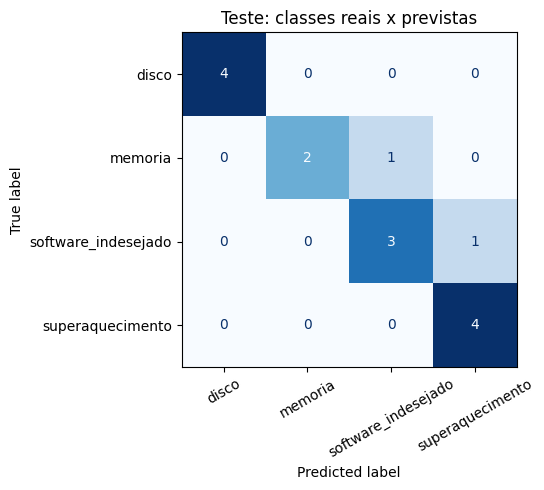

In [5]:
# Matriz de confusão em formato gráfico
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(
    cmap="Blues", colorbar=False, ax=ax, xticks_rotation=30
)
ax.set_title("Teste: classes reais x previstas")
plt.tight_layout()
plt.show()

Condições aprendidas:
|--- temperatura <= 77.00
|   |--- uso_memoria <= 88.50
|   |   |--- uso_memoria <= 62.00
|   |   |   |--- class: disco
|   |   |--- uso_memoria >  62.00
|   |   |   |--- class: software_indesejado
|   |--- uso_memoria >  88.50
|   |   |--- uso_disco <= 60.00
|   |   |   |--- class: memoria
|   |   |--- uso_disco >  60.00
|   |   |   |--- class: software_indesejado
|--- temperatura >  77.00
|   |--- class: superaquecimento

Importância dos atributos:
uso_memoria         0.595
temperatura         0.347
uso_disco           0.058
instalou_recente    0.000
dtype: float64


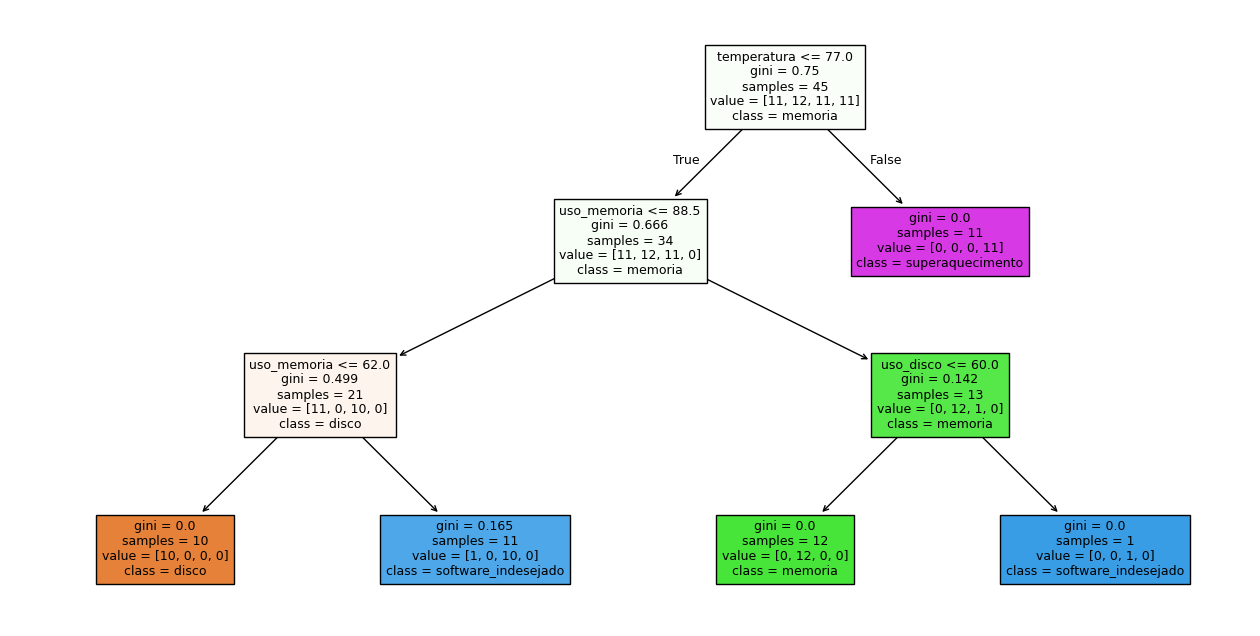

In [6]:
# Regras (condições) que a árvore aprendeu, em formato de texto
print("Condições aprendidas:")
print(export_text(modelo, feature_names=ATRIBUTOS))

# Importância de cada atributo na decisão da árvore
importancias = (pd.Series(modelo.feature_importances_, index=ATRIBUTOS)
                  .sort_values(ascending=False).round(3))
print("Importância dos atributos:")
print(importancias)

# Estrutura da árvore em formato gráfico
plt.figure(figsize=(16, 8))
plot_tree(modelo, feature_names=ATRIBUTOS,
          class_names=classes, filled=True, fontsize=9)
plt.show()

In [7]:
# Exemplos de teste que o modelo errou (para a análise do item 7)
erros = X_teste.assign(real=y_teste, previsto=previsoes)
erros = erros[erros["real"] != erros["previsto"]]

if erros.empty:
    print("Nenhum erro neste conjunto de teste.")
else:
    print(f"{len(erros)} erro(s) no teste:")
    print(erros.to_string())

2 erro(s) no teste:
    uso_disco  uso_memoria  temperatura  instalou_recente                 real             previsto
36         46           81           79                 1  software_indesejado     superaquecimento
27         23           86           60                 0              memoria  software_indesejado


### Como ler os termos da árvore

Cada caixa (nó) mostra:
- **Condição** de divisão (ex.: `temperatura <= 77`): o teste que separa os exemplos.
- **gini**: impureza do nó. `0.0` = todos os exemplos são da mesma classe; quanto maior, mais misturado.
- **samples**: quantos exemplos de **treino** chegaram naquele nó.
- **value**: quantos exemplos de cada classe há no nó, na ordem alfabética das classes.
- **class**: a classe majoritária, que será a previsão se o caso terminar naquele nó.

**Interpretação.** A acurácia vem de apenas 15 exemplos de teste, e cada erro vale cerca de 6,7 pontos percentuais. Além disso, os dados foram **gerados por nós a partir de perfis**, então a árvore só "redescobre" a regra de simulação. **Uma boa acurácia aqui não prova eficácia em computadores reais.**

## 6. Base de conhecimento e motor de inferência

A previsão do modelo vira o fato **`causa_prevista`**. O outro fato, informado pelo usuário, é **`pc_antigo`**. O motor procura a regra compatível e devolve diagnóstico, recomendação e justificativa.

### Regras e sua origem (item 2 da atividade)

São **9 regras escritas por pessoas** (não aprendidas pela árvore):

| Regra | SE causa prevista | E PC antigo | ENTÃO | Origem da regra |
|---|---|---|---|---|
| R1 | disco | sim | D08 | DiagPC D08 ("considerar SSD"); heurística: PC com mais de 5 anos costuma ter HD mecânico |
| R2 | disco | não | D08 | DiagPC D08 (liberar espaço, verificar saúde do disco) |
| R3 | memoria | sim | D09 | DiagPC D09 ("considerar mais RAM"); PC antigo costuma ter pouca RAM |
| R4 | memoria | não | D09 | DiagPC D09 (fechar programas, reduzir inicialização) |
| R5 | superaquecimento | sim | D10 | DiagPC D10; pasta térmica ressecada é comum em PC antigo |
| R6 | superaquecimento | não | D10 | DiagPC D10 (limpar poeira, verificar ventoinhas) |
| R7 | software_indesejado | sim | D11 | DiagPC D11; em PC antigo, reinstalar o sistema compensa mais |
| R8 | software_indesejado | não | D11 | DiagPC D11 (desinstalar o programa recente, antivírus) |
| R9 | confiança baixa ou nenhuma regra serve | | D00 | DiagPC R20 (diagnóstico inconclusivo: procurar técnico) |

**Origem:** os diagnósticos D08 a D11 vêm da Base de Conhecimento do DiagPC (seção 7.4 do documento). A separação entre "PC antigo" e "PC novo" é uma **heurística que eu propus e que ainda deve ser validada em entrevista com o técnico de suporte** (engenheiro do conhecimento ↔ especialista de domínio).

### Fallback de segurança
Se o modelo estiver **pouco confiante** (probabilidade da classe prevista abaixo de `LIMIAR_CONFIANCA`), o sistema **não arrisca**: dispara a R9 e recomenda um técnico. É o equivalente ao "não sei" do DiagPC.

In [8]:
# Abaixo desta confiança do modelo, o sistema declara o caso inconclusivo
LIMIAR_CONFIANCA = 0.60

# ------------------------- BASE DE CONHECIMENTO -------------------------
# Regras SE-ENTÃO escritas por pessoas. Para mudar uma recomendação,
# basta editar esta lista: o motor abaixo não precisa ser alterado.
regras = [
    {"id": "R1", "causa": "disco", "pc_antigo": True, "diagnostico": "D08",
     "acao": "Fazer backup, liberar espaço, verificar a saúde do disco e "
             "considerar trocar o HD por um SSD."},
    {"id": "R2", "causa": "disco", "pc_antigo": False, "diagnostico": "D08",
     "acao": "Liberar espaço, reduzir programas na inicialização e "
             "verificar a saúde do disco."},
    {"id": "R3", "causa": "memoria", "pc_antigo": True, "diagnostico": "D09",
     "acao": "Fechar programas e reduzir a inicialização automática; "
             "considerar aumentar a memória RAM."},
    {"id": "R4", "causa": "memoria", "pc_antigo": False, "diagnostico": "D09",
     "acao": "Fechar programas e abas em segundo plano e reduzir a "
             "inicialização automática."},
    {"id": "R5", "causa": "superaquecimento", "pc_antigo": True,
     "diagnostico": "D10",
     "acao": "Limpar a poeira, verificar as ventoinhas e trocar a pasta "
             "térmica (assistência técnica)."},
    {"id": "R6", "causa": "superaquecimento", "pc_antigo": False,
     "diagnostico": "D10",
     "acao": "Limpar a poeira, melhorar a ventilação e conferir se as "
             "ventoinhas giram."},
    {"id": "R7", "causa": "software_indesejado", "pc_antigo": True,
     "diagnostico": "D11",
     "acao": "Desinstalar o programa recente, rodar o antivírus e, se "
             "persistir, considerar reinstalar o sistema."},
    {"id": "R8", "causa": "software_indesejado", "pc_antigo": False,
     "diagnostico": "D11",
     "acao": "Desinstalar o programa recente e rodar o antivírus."},
]

REGRA_INCONCLUSIVA = {
    "id": "R9", "diagnostico": "D00",
    "acao": "Diagnóstico inconclusivo: procurar um técnico presencialmente."
}

# ------------------------- MOTOR DE INFERÊNCIA -------------------------
def aplicar_regras(causa_prevista, confianca, pc_antigo):
    """Cruza os fatos com a Base e devolve a regra disparada."""
    # Modelo pouco confiante -> não arriscar (equivalente ao "não sei")
    if confianca < LIMIAR_CONFIANCA:
        return {
            "regra": REGRA_INCONCLUSIVA["id"],
            "diagnostico": REGRA_INCONCLUSIVA["diagnostico"],
            "recomendacao": REGRA_INCONCLUSIVA["acao"],
            "explicacao": (f"O modelo previu '{causa_prevista}' com "
                           f"confiança de apenas {confianca:.0%} "
                           f"(mínimo exigido: {LIMIAR_CONFIANCA:.0%}).")
        }

    # Procura a primeira regra cujas condições coincidem com os fatos
    for r in regras:
        if r["causa"] == causa_prevista and r["pc_antigo"] == pc_antigo:
            return {
                "regra": r["id"],
                "diagnostico": r["diagnostico"],
                "recomendacao": r["acao"],
                "explicacao": (
                    f"Fato 1 (previsto pelo modelo): causa = "
                    f"'{causa_prevista}' (confiança {confianca:.0%}). "
                    f"Fato 2 (informado pelo usuário): PC com mais de 5 "
                    f"anos = {pc_antigo}. A regra {r['id']} dispara e "
                    f"conclui {r['diagnostico']}.")
            }

    # Nenhuma regra serve -> inconclusivo (R20 do DiagPC)
    return {
        "regra": REGRA_INCONCLUSIVA["id"],
        "diagnostico": REGRA_INCONCLUSIVA["diagnostico"],
        "recomendacao": REGRA_INCONCLUSIVA["acao"],
        "explicacao": "Nenhuma regra da Base cobre esta combinação de fatos."
    }

# Mostra a Base de forma tabular (útil para revisar com o especialista)
print(pd.DataFrame(regras)[["id", "causa", "pc_antigo", "diagnostico"]]
      .to_string(index=False))

id               causa  pc_antigo diagnostico
R1               disco       True         D08
R2               disco      False         D08
R3             memoria       True         D09
R4             memoria      False         D09
R5    superaquecimento       True         D10
R6    superaquecimento      False         D10
R7 software_indesejado       True         D11
R8 software_indesejado      False         D11


## 7. Integrar o modelo ao sistema especialista

A função valida as entradas, usa o **modelo** para prever a causa, calcula a **confiança** (probabilidade da classe prevista) e chama o **motor**. Valores **fora dos intervalos vistos no treino** recebem um aviso, porque a previsão pode ser menos confiável.

In [9]:
def orientar_pc(uso_disco, uso_memoria, temperatura,
                instalou_recente, pc_antigo):
    """Integra o classificador (ML) ao motor de regras (sistema especialista)."""
    # --- Validações das entradas ---
    if not 0 <= uso_disco <= 100:
        raise ValueError("Uso do disco deve estar entre 0 e 100.")
    if not 0 <= uso_memoria <= 100:
        raise ValueError("Uso de memória deve estar entre 0 e 100.")
    if not 0 <= temperatura <= 120:
        raise ValueError("Temperatura deve estar entre 0 e 120 °C.")
    if not isinstance(instalou_recente, bool):
        raise ValueError("instalou_recente deve ser True ou False.")
    if not isinstance(pc_antigo, bool):
        raise ValueError("pc_antigo deve ser True ou False.")

    # Novo caso no mesmo formato (e ordem de colunas) usado no treino
    novo_caso = pd.DataFrame([{
        "uso_disco": uso_disco,
        "uso_memoria": uso_memoria,
        "temperatura": temperatura,
        "instalou_recente": int(instalou_recente),
    }])[ATRIBUTOS]

    # 1) CLASSIFICAÇÃO: o modelo prevê a causa e informa a confiança
    probabilidades = modelo.predict_proba(novo_caso)[0]
    posicao = probabilidades.argmax()
    causa_prevista = modelo.classes_[posicao]
    confianca = float(probabilidades[posicao])

    # 2) INFERÊNCIA: a previsão vira fato e o motor aplica as regras
    resultado = aplicar_regras(causa_prevista, confianca, pc_antigo)
    resultado = {"causa_prevista": causa_prevista,
                 "confianca": f"{confianca:.0%}", **resultado}

    # Aviso se a entrada estiver fora do intervalo observado no treino
    fora = [c for c in ["uso_disco", "uso_memoria", "temperatura"]
            if not X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max()]
    resultado["aviso"] = (
        f"Entrada fora dos intervalos do treino em: {', '.join(fora)}. "
        "Previsão menos confiável." if fora
        else "Exemplo didático; orientação sujeita a revisão humana."
    )
    return resultado


def mostrar(resultado):
    """Imprime o resultado campo a campo."""
    for campo, valor in resultado.items():
        print(f"{campo}: {valor}")

## 8. Três novos casos (item 6 da atividade)

Casos **que não estão no dataset de treino nem no de teste**. Cada um mostra a previsão do modelo, a regra aplicada e a explicação.

In [10]:
# (uso_disco, uso_memoria, temperatura, instalou_recente, pc_antigo)
casos = [
    (98, 50, 52, False, True),    # disco cheio em PC antigo
    (62, 78, 66, True,  False),   # instalou algo e o PC piorou
    (35, 55, 90, False, True),    # PC muito quente
]

for i, (d, m, t, inst, antigo) in enumerate(casos, 1):
    print(f"\n=== CASO {i}: disco={d}%  memória={m}%  temp={t}°C  "
          f"instalou_recente={inst}  pc_antigo={antigo}")
    mostrar(orientar_pc(d, m, t, inst, antigo))


=== CASO 1: disco=98%  memória=50%  temp=52°C  instalou_recente=False  pc_antigo=True
causa_prevista: disco
confianca: 100%
regra: R1
diagnostico: D08
recomendacao: Fazer backup, liberar espaço, verificar a saúde do disco e considerar trocar o HD por um SSD.
explicacao: Fato 1 (previsto pelo modelo): causa = 'disco' (confiança 100%). Fato 2 (informado pelo usuário): PC com mais de 5 anos = True. A regra R1 dispara e conclui D08.
aviso: Exemplo didático; orientação sujeita a revisão humana.

=== CASO 2: disco=62%  memória=78%  temp=66°C  instalou_recente=True  pc_antigo=False
causa_prevista: software_indesejado
confianca: 91%
regra: R8
diagnostico: D11
recomendacao: Desinstalar o programa recente e rodar o antivírus.
explicacao: Fato 1 (previsto pelo modelo): causa = 'software_indesejado' (confiança 91%). Fato 2 (informado pelo usuário): PC com mais de 5 anos = False. A regra R8 dispara e conclui D11.
aviso: Exemplo didático; orientação sujeita a revisão humana.

=== CASO 3: disco=35% 

### Comparação: mesma previsão, resposta diferente do usuário

Qual componente modifica a recomendação? Vamos manter as métricas iguais (**mesma previsão do modelo**) e alterar só a resposta `pc_antigo`.

In [11]:
for antigo in (True, False):
    r = orientar_pc(98, 50, 52, False, antigo)
    print(f"pc_antigo={antigo!s:5} -> previsão: {r['causa_prevista']} "
          f"| regra {r['regra']} | {r['recomendacao']}")

pc_antigo=True  -> previsão: disco | regra R1 | Fazer backup, liberar espaço, verificar a saúde do disco e considerar trocar o HD por um SSD.
pc_antigo=False -> previsão: disco | regra R2 | Liberar espaço, reduzir programas na inicialização e verificar a saúde do disco.


**Resposta:** a previsão do modelo foi a mesma nos dois casos (`disco`), mas a recomendação mudou (R1 x R2). Quem modifica a recomendação é o **sistema especialista**: o motor combina a previsão com o fato informado pelo usuário. O modelo de ML só **transforma métricas em um fato**; a decisão de *o que fazer* continua nas regras escritas por pessoas, que podem ser lidas, auditadas e editadas.

In [12]:
# 1) Caso na "fronteira" entre classes (métricas medianas em tudo)
print("=== 1) Caso ambíguo (disco=70, memória=70, temp=70, sem instalação)")
mostrar(orientar_pc(70, 70, 70, False, False))

# 2) Demonstração da R9: simulamos um modelo pouco confiante (45%),
#    chamando o motor diretamente com essa confiança
print("\n=== 2) Motor com confiança simulada de 45% (aciona a R9)")
mostrar(aplicar_regras("disco", 0.45, False))

# 3) Caso com temperatura acima do que o treino já viu
print("\n=== 3) Fora do intervalo do treino (temperatura 110 °C)")
mostrar(orientar_pc(40, 50, 110, False, True))

=== 1) Caso ambíguo (disco=70, memória=70, temp=70, sem instalação)
causa_prevista: software_indesejado
confianca: 91%
regra: R8
diagnostico: D11
recomendacao: Desinstalar o programa recente e rodar o antivírus.
explicacao: Fato 1 (previsto pelo modelo): causa = 'software_indesejado' (confiança 91%). Fato 2 (informado pelo usuário): PC com mais de 5 anos = False. A regra R8 dispara e conclui D11.
aviso: Exemplo didático; orientação sujeita a revisão humana.

=== 2) Motor com confiança simulada de 45% (aciona a R9)
regra: R9
diagnostico: D00
recomendacao: Diagnóstico inconclusivo: procurar um técnico presencialmente.
explicacao: O modelo previu 'disco' com confiança de apenas 45% (mínimo exigido: 60%).

=== 3) Fora do intervalo do treino (temperatura 110 °C)
causa_prevista: superaquecimento
confianca: 100%
regra: R5
diagnostico: D10
recomendacao: Limpar a poeira, verificar as ventoinhas e trocar a pasta térmica (assistência técnica).
explicacao: Fato 1 (previsto pelo modelo): causa = 's

### Casos de borda: confiança do modelo, regra inconclusiva e entrada fora do treino

Três situações para testar os limites do sistema:
1. um caso na "fronteira" entre classes (métricas medianas);
2. o motor recebendo uma **confiança baixa** (simulada), para mostrar a regra **R9**;
3. uma temperatura acima de tudo o que o treino já viu.

## 9. Experimente uma consulta

Altere os valores abaixo e execute novamente.

In [13]:
uso_disco = 97
uso_memoria = 60
temperatura = 54


In [14]:
instalou_recente = False
pc_antigo = False

mostrar(orientar_pc(uso_disco, uso_memoria, temperatura,
                    instalou_recente, pc_antigo))

causa_prevista: disco
confianca: 100%
regra: R2
diagnostico: D08
recomendacao: Liberar espaço, reduzir programas na inicialização e verificar a saúde do disco.
explicacao: Fato 1 (previsto pelo modelo): causa = 'disco' (confiança 100%). Fato 2 (informado pelo usuário): PC com mais de 5 anos = False. A regra R2 dispara e conclui D08.
aviso: Exemplo didático; orientação sujeita a revisão humana.


## 10. Análise dos resultados, erros e limitações (item 7)

### 10.1 Resultados

- **Acurácia no teste: 86,7%** (13 acertos em 15). Na validação cruzada dentro do treino, a média foi de **93,3%**.
- A diferença entre os dois valores é esperada: o teste tem só 15 exemplos, então **cada erro vale cerca de 6,7 pontos percentuais**. Com tão poucos casos, não dá para afirmar qual das duas medidas está mais perto do desempenho "verdadeiro".
- A classe `disco` foi a mais fácil (4 de 4): o uso de disco perto de 100% é um sinal muito forte. As classes `memoria` e `software_indesejado` foram as mais confundidas, porque seus perfis simulados se sobrepõem (as duas têm memória alta).

### 10.2 Erros do modelo

O modelo errou 2 dos 15 exemplos de teste:

| Real | Previsto | Por quê |
|---|---|---|
| `software_indesejado` (disco 46%, memória 81%, temp 79 °C) | `superaquecimento` | A temperatura de 79 °C passou do limite aprendido (77 °C), embora a causa real fosse outra. Caso **na fronteira** da regra. |
| `memoria` (disco 23%, memória 86%, temp 60 °C) | `software_indesejado` | A memória de 86% ficou abaixo do limite aprendido (88,5%), então o caso não chegou ao ramo de `memoria`. Novamente um caso **na fronteira**. |

Os dois erros ocorreram **perto de limiares** da árvore. A árvore aprendeu cortes rígidos (por exemplo, `temperatura <= 77`) com base em poucos exemplos, e a simulação usa ruído que faz as classes se tocarem.

**Efeito no sistema especialista:** um erro do modelo **se propaga** para a recomendação. Se o modelo prevê `superaquecimento` por engano, a regra R5/R6 manda limpar o PC, e o problema real (software) continua. A regra em si estaria correta, mas o fato que ela recebeu estaria errado. Por isso o sistema mantém o aviso de "sujeito a revisão humana".

### 10.3 Limitações

- **Dados simulados e pequenos.** São 60 exemplos gerados por código, e os rótulos vêm do próprio gerador. A acurácia mede se a árvore "redescobre" os perfis que nós mesmos definimos, **não** se ela diagnostica computadores reais.
- **Atributo ignorado.** `instalou_recente` teve importância 0 na árvore: ela separou `software_indesejado` só por memória e disco. Na simulação, essa classe tem disco e memória "moderadamente altos", mas a instalação recente seria o sinal mais coerente. Em um projeto real eu revisaria os atributos ou usaria mais dados para ver se ela passa a ser usada.
- **Superconfiança.** A probabilidade de uma árvore pequena é pouco calibrada. No caso de métricas medianas (70/70/70), o modelo ainda respondeu com mais de 90% de confiança. Por isso o limiar `LIMIAR_CONFIANCA` quase nunca aciona sozinho a regra inconclusiva R9.
- **Uma causa por vez.** O modelo escolhe uma única causa, mas um PC real pode ter várias ao mesmo tempo (por exemplo, memória cheia **e** muito quente). O DiagPC também assume uma queixa principal por consulta.
- **Dependência do relato do usuário.** Os valores de disco, memória e temperatura são digitados pelo usuário; o sistema não mede o hardware (limitação já registrada no DiagPC). A resposta `pc_antigo` também parte da premissa de que o usuário responde com honestidade.
- **Regras de `pc_antigo` não validadas.** A divisão entre PC antigo e novo é heurística minha e ainda precisa ser confirmada com o técnico de suporte.

### 10.4 Exemplos pouco representados

O dataset **não cobre**, e portanto o modelo não sabe lidar com:
- **Casos com duas causas ao mesmo tempo** (por exemplo, memória em 95% e temperatura em 85 °C).
- **Valores extremos**: o dataset só tem temperaturas entre 42 °C e 100 °C. O código emite um aviso quando a entrada sai do intervalo visto no treino (demonstrado com 110 °C), mas o modelo apenas extrapola o último corte aprendido, sem "saber" nada sobre essa faixa.
- **Tipos de máquina**: HD x SSD, notebook x desktop, sistemas operacionais diferentes. Cada um tem faixas normais de temperatura e de uso diferentes.
- **Causas de lentidão fora das quatro classes** (rede, driver, vírus pesado, disco com defeito físico). Nesses casos o modelo sempre devolve uma das quatro causas, mesmo que nenhuma esteja certa. Não existe uma classe "nenhuma das anteriores".
- **Poucas amostras por classe no teste** (3 ou 4), o que torna a avaliação de cada classe pouco confiável.

### 10.5 Papel de cada componente

| Componente | O que faz | Vantagem | Limite |
|---|---|---|---|
| **Árvore de decisão (ML)** | Aprende os limiares a partir de exemplos e produz o fato `causa_prevista` | Não exige que alguém defina os cortes (77 °C, 88,5%) à mão | Depende de dados rotulados; pode errar perto das fronteiras |
| **Regras (sistema especialista)** | Combinam o fato previsto com o fato do usuário e decidem a recomendação | Legíveis, explicáveis e editáveis sem retreinar | Escritas por pessoas; dependem do conhecimento do técnico |

## 11. Conclusão

- O **classificador** converte métricas numéricas em um **fato simbólico** (`causa_prevista`), algo que as regras sozinhas não conseguem sem limiares fixos escritos à mão.
- O **sistema especialista** mantém as vantagens do DiagPC: regras legíveis, separação entre Base e Motor, explicação de cada conclusão e recomendação de técnico quando há dúvida.
- A abordagem **híbrida** une o melhor dos dois mundos, mas a qualidade do conjunto depende de **bons dados rotulados**. Neste trabalho eles foram simulados, então os números têm valor **didático**.